# Scenario 1 - Dynamic Pricing for a Ride-Sharing Platform
### 43008 Reinforcement Learning - Assignment 1 (Spring 2026)

This notebook formulates the compulsory Dynamic Pricing for a Ride-Sharing Platform case study as a finite-horizon MDP (T = 12) and solves it with Value Iteration (backward induction) and Policy Iteration. It then simulates the optimal policies and compares the two algorithms. The 2-hour window uses time-varying transition probabilities `P_t` (evening peak easing into the late night), so the optimal policy is non-stationary. Full rationale for the model is in the report.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RNG_SEED = 42
np.random.seed(RNG_SEED)
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
print("Environment ready. numpy", np.__version__)

Environment ready. numpy 2.0.2


## 1. MDP Formulation

One zone, a 2-hour window, a decision every 10 min → finite-horizon MDP with T = 12 (`t = 0…11`, episode ends at `t = 12`). The state is fully observed; action effects are stochastic. The full rationale for every state, action, reward and transition value is in the report (§2, MDP Formulation) — this notebook keeps only what is needed to follow the code.

### 1.1 States (S = 9) — demand/supply balance in the zone
`BALANCED`, `MILD / MODERATE / SEVERE_UNDERSUPPLY`, `MILD / MODERATE / SEVERE_OVERSUPPLY`, `LOW_DRIVER_BASE` (structurally few drivers — looks like a demand spike but needs a supply-side fix), `CRITICAL_BACKLOG` (queue collapse — crisis state).

### 1.2 Actions (A = 5)
`HOLD`, `RAISE_PRICE`, `LOWER_PRICE`, `DRIVER_INCENTIVE`, `PAUSE_NEW_REQUESTS`.

### 1.3 Reward  `R(s, a) = operating_value(s) + action_cost(s, a)`
`operating_value` rewards a balanced zone (under-supply penalised harder than over-supply; `CRITICAL_BACKLOG` heavily). `action_cost` = a base cost per action + state-dependent surcharges for using a lever where the brief says it backfires. Terminal value `V_T(s) = operating_value(s)`.

### 1.4 Transitions — time-varying `P_t`
A hand-designed phase-neutral base `P_base(s'|s, a)` (intended effect = mode of the distribution; severity moves one notch at a time; the bad states carry a tail risk to a worse state), reweighted each phase for the evening-peak → late-night cycle through three daily-rhythm channels (`demand_pressure`, `driver_attrition`, `price_efficacy`). Every `P_t(·|s, a)` row is renormalised to 1. Values and derivation: report §2.

In [2]:
STATES = ["BALANCED", "MILD_UNDERSUPPLY", "MODERATE_UNDERSUPPLY", "SEVERE_UNDERSUPPLY",
          "MILD_OVERSUPPLY", "MODERATE_OVERSUPPLY", "SEVERE_OVERSUPPLY",
          "LOW_DRIVER_BASE", "CRITICAL_BACKLOG"]
ACTIONS = ["HOLD", "RAISE_PRICE", "LOWER_PRICE", "DRIVER_INCENTIVE", "PAUSE_NEW_REQUESTS"]
S, A = len(STATES), len(ACTIONS)
HORIZON = 12

s_idx = {name: i for i, name in enumerate(STATES)}
a_idx = {name: i for i, name in enumerate(ACTIONS)}
BAL, MU, MOD_U, SU, MO, MOD_O, SO, LOW, CRIT = range(S)   # short state handles used below

PHASES = ["A", "B", "C", "D"]
def phase_of(t): return PHASES[min(t // 3, 3)]          # 3 periods per phase
#                (demand_pressure, driver_attrition, price_efficacy) per phase
PHASE_PARAMS = {"A": (1.20, 0.00, 1.00),
                "B": (0.95, 0.10, 1.00),
                "C": (0.05, 0.55, 0.78),
                "D": (0.00, 1.70, 0.40)}

print(f"S = {S} states, A = {A} actions, finite horizon T = {HORIZON}")

S = 9 states, A = 5 actions, finite horizon T = 12


In [3]:
# ---- Reward model --------------------------------------------------------------
operating_value = np.array([
    10.0,   # BALANCED
     5.0,   # MILD_UNDERSUPPLY
    -1.0,   # MODERATE_UNDERSUPPLY
    -7.0,   # SEVERE_UNDERSUPPLY
     4.0,   # MILD_OVERSUPPLY
    -1.0,   # MODERATE_OVERSUPPLY
    -5.0,   # SEVERE_OVERSUPPLY
    -3.0,   # LOW_DRIVER_BASE
   -16.0,   # CRITICAL_BACKLOG
])

base_action_cost = {
    "HOLD": 0.0, "RAISE_PRICE": -1.0, "LOWER_PRICE": -2.0,
    "DRIVER_INCENTIVE": -4.0, "PAUSE_NEW_REQUESTS": -6.0,
}

def action_cost(s, a):
    cost = base_action_cost[ACTIONS[a]]
    name = ACTIONS[a]
    if name == "RAISE_PRICE" and s in (BAL, MO, MOD_O, SO):
        cost -= 4.0
    if name == "LOWER_PRICE" and s in (MOD_U, SU, LOW, CRIT):
        cost -= 4.0
    if name == "DRIVER_INCENTIVE" and s in (BAL, MO, MOD_O, SO):
        cost -= 3.0
    return cost

def reward(s, a):
    """R(s, a) = operating value of the state + cost of the action (no time-of-use term here)."""
    return operating_value[s] + action_cost(s, a)

R = np.array([[reward(s, a) for a in range(A)] for s in range(S)])
R_time = np.broadcast_to(R, (HORIZON, S, A))            # reward does not depend on t here
terminal_value = operating_value.copy()

print("Reward matrix R(s, a):")
print(pd.DataFrame(R, index=STATES, columns=ACTIONS).round(1))

Reward matrix R(s, a):
                      HOLD  RAISE_PRICE  LOWER_PRICE  DRIVER_INCENTIVE  PAUSE_NEW_REQUESTS
BALANCED              10.0          5.0          8.0               3.0                 4.0
MILD_UNDERSUPPLY       5.0          4.0          3.0               1.0                -1.0
MODERATE_UNDERSUPPLY  -1.0         -2.0         -7.0              -5.0                -7.0
SEVERE_UNDERSUPPLY    -7.0         -8.0        -13.0             -11.0               -13.0
MILD_OVERSUPPLY        4.0         -1.0          2.0              -3.0                -2.0
MODERATE_OVERSUPPLY   -1.0         -6.0         -3.0              -8.0                -7.0
SEVERE_OVERSUPPLY     -5.0        -10.0         -7.0             -12.0               -11.0
LOW_DRIVER_BASE       -3.0         -4.0         -9.0              -7.0                -9.0
CRITICAL_BACKLOG     -16.0        -17.0        -22.0             -20.0               -22.0


In [4]:
# ---- Base (phase-neutral) transition model  P_base  ---------------------------
# BASE_SPEC[(state, action)] = { next_state: relative weight, ... }; rows renormalised to 1.
BASE_SPEC = {
    # HOLD
    ("BALANCED", "HOLD"): {"BALANCED": 0.62, "MILD_UNDERSUPPLY": 0.13, "MILD_OVERSUPPLY": 0.13, "LOW_DRIVER_BASE": 0.05, "MODERATE_UNDERSUPPLY": 0.03, "MODERATE_OVERSUPPLY": 0.03, "SEVERE_UNDERSUPPLY": 0.005, "SEVERE_OVERSUPPLY": 0.005},
    ("MILD_UNDERSUPPLY", "HOLD"): {"BALANCED": 0.45, "MILD_UNDERSUPPLY": 0.38, "MODERATE_UNDERSUPPLY": 0.12, "LOW_DRIVER_BASE": 0.05},
    ("MODERATE_UNDERSUPPLY", "HOLD"): {"MODERATE_UNDERSUPPLY": 0.4, "MILD_UNDERSUPPLY": 0.28, "SEVERE_UNDERSUPPLY": 0.22, "BALANCED": 0.1},
    ("SEVERE_UNDERSUPPLY", "HOLD"): {"SEVERE_UNDERSUPPLY": 0.44, "MODERATE_UNDERSUPPLY": 0.28, "CRITICAL_BACKLOG": 0.18, "MILD_UNDERSUPPLY": 0.1},
    ("MILD_OVERSUPPLY", "HOLD"): {"BALANCED": 0.45, "MILD_OVERSUPPLY": 0.38, "MODERATE_OVERSUPPLY": 0.12, "LOW_DRIVER_BASE": 0.05},
    ("MODERATE_OVERSUPPLY", "HOLD"): {"MODERATE_OVERSUPPLY": 0.42, "MILD_OVERSUPPLY": 0.3, "SEVERE_OVERSUPPLY": 0.2, "BALANCED": 0.08},
    ("SEVERE_OVERSUPPLY", "HOLD"): {"SEVERE_OVERSUPPLY": 0.46, "MODERATE_OVERSUPPLY": 0.3, "MILD_OVERSUPPLY": 0.14, "LOW_DRIVER_BASE": 0.1},
    ("LOW_DRIVER_BASE", "HOLD"): {"LOW_DRIVER_BASE": 0.52, "MILD_UNDERSUPPLY": 0.22, "MODERATE_UNDERSUPPLY": 0.16, "BALANCED": 0.1},
    ("CRITICAL_BACKLOG", "HOLD"): {"CRITICAL_BACKLOG": 0.5, "SEVERE_UNDERSUPPLY": 0.34, "MODERATE_UNDERSUPPLY": 0.11, "BALANCED": 0.05},
    # RAISE_PRICE
    ("BALANCED", "RAISE_PRICE"): {"MILD_OVERSUPPLY": 0.4, "BALANCED": 0.34, "MODERATE_OVERSUPPLY": 0.16, "MILD_UNDERSUPPLY": 0.1},
    ("MILD_UNDERSUPPLY", "RAISE_PRICE"): {"BALANCED": 0.56, "MILD_UNDERSUPPLY": 0.22, "MILD_OVERSUPPLY": 0.12, "MODERATE_UNDERSUPPLY": 0.1},
    ("MODERATE_UNDERSUPPLY", "RAISE_PRICE"): {"MILD_UNDERSUPPLY": 0.48, "BALANCED": 0.28, "MODERATE_UNDERSUPPLY": 0.18, "SEVERE_UNDERSUPPLY": 0.06},
    ("SEVERE_UNDERSUPPLY", "RAISE_PRICE"): {"MODERATE_UNDERSUPPLY": 0.44, "SEVERE_UNDERSUPPLY": 0.26, "MILD_UNDERSUPPLY": 0.24, "CRITICAL_BACKLOG": 0.06},
    ("MILD_OVERSUPPLY", "RAISE_PRICE"): {"MODERATE_OVERSUPPLY": 0.44, "MILD_OVERSUPPLY": 0.34, "SEVERE_OVERSUPPLY": 0.16, "BALANCED": 0.06},
    ("MODERATE_OVERSUPPLY", "RAISE_PRICE"): {"SEVERE_OVERSUPPLY": 0.46, "MODERATE_OVERSUPPLY": 0.34, "MILD_OVERSUPPLY": 0.14, "BALANCED": 0.06},
    ("SEVERE_OVERSUPPLY", "RAISE_PRICE"): {"SEVERE_OVERSUPPLY": 0.6, "MODERATE_OVERSUPPLY": 0.3, "MILD_OVERSUPPLY": 0.1},
    ("LOW_DRIVER_BASE", "RAISE_PRICE"): {"MILD_UNDERSUPPLY": 0.4, "LOW_DRIVER_BASE": 0.3, "BALANCED": 0.24, "MODERATE_UNDERSUPPLY": 0.06},
    ("CRITICAL_BACKLOG", "RAISE_PRICE"): {"SEVERE_UNDERSUPPLY": 0.44, "CRITICAL_BACKLOG": 0.34, "MODERATE_UNDERSUPPLY": 0.16, "MILD_UNDERSUPPLY": 0.06},
    # LOWER_PRICE
    ("BALANCED", "LOWER_PRICE"): {"MILD_UNDERSUPPLY": 0.4, "BALANCED": 0.34, "MODERATE_UNDERSUPPLY": 0.16, "MILD_OVERSUPPLY": 0.1},
    ("MILD_UNDERSUPPLY", "LOWER_PRICE"): {"MODERATE_UNDERSUPPLY": 0.44, "MILD_UNDERSUPPLY": 0.34, "SEVERE_UNDERSUPPLY": 0.16, "BALANCED": 0.06},
    ("MODERATE_UNDERSUPPLY", "LOWER_PRICE"): {"SEVERE_UNDERSUPPLY": 0.48, "MODERATE_UNDERSUPPLY": 0.3, "CRITICAL_BACKLOG": 0.16, "MILD_UNDERSUPPLY": 0.06},
    ("SEVERE_UNDERSUPPLY", "LOWER_PRICE"): {"CRITICAL_BACKLOG": 0.5, "SEVERE_UNDERSUPPLY": 0.4, "MODERATE_UNDERSUPPLY": 0.1},
    ("MILD_OVERSUPPLY", "LOWER_PRICE"): {"BALANCED": 0.54, "MILD_OVERSUPPLY": 0.24, "MILD_UNDERSUPPLY": 0.22},
    ("MODERATE_OVERSUPPLY", "LOWER_PRICE"): {"MILD_OVERSUPPLY": 0.48, "BALANCED": 0.34, "MODERATE_OVERSUPPLY": 0.18},
    ("SEVERE_OVERSUPPLY", "LOWER_PRICE"): {"MODERATE_OVERSUPPLY": 0.48, "MILD_OVERSUPPLY": 0.32, "BALANCED": 0.12, "SEVERE_OVERSUPPLY": 0.08},
    ("LOW_DRIVER_BASE", "LOWER_PRICE"): {"SEVERE_UNDERSUPPLY": 0.44, "LOW_DRIVER_BASE": 0.28, "CRITICAL_BACKLOG": 0.22, "MODERATE_UNDERSUPPLY": 0.06},
    ("CRITICAL_BACKLOG", "LOWER_PRICE"): {"CRITICAL_BACKLOG": 0.7, "SEVERE_UNDERSUPPLY": 0.24, "MODERATE_UNDERSUPPLY": 0.06},
    # DRIVER_INCENTIVE
    ("BALANCED", "DRIVER_INCENTIVE"): {"MILD_OVERSUPPLY": 0.44, "BALANCED": 0.34, "MODERATE_OVERSUPPLY": 0.22},
    ("MILD_UNDERSUPPLY", "DRIVER_INCENTIVE"): {"BALANCED": 0.58, "MILD_OVERSUPPLY": 0.22, "MILD_UNDERSUPPLY": 0.2},
    ("MODERATE_UNDERSUPPLY", "DRIVER_INCENTIVE"): {"MILD_UNDERSUPPLY": 0.46, "BALANCED": 0.34, "MODERATE_UNDERSUPPLY": 0.14, "MILD_OVERSUPPLY": 0.06},
    ("SEVERE_UNDERSUPPLY", "DRIVER_INCENTIVE"): {"MODERATE_UNDERSUPPLY": 0.44, "MILD_UNDERSUPPLY": 0.3, "SEVERE_UNDERSUPPLY": 0.18, "BALANCED": 0.08},
    ("MILD_OVERSUPPLY", "DRIVER_INCENTIVE"): {"MODERATE_OVERSUPPLY": 0.48, "MILD_OVERSUPPLY": 0.4, "BALANCED": 0.12},
    ("MODERATE_OVERSUPPLY", "DRIVER_INCENTIVE"): {"SEVERE_OVERSUPPLY": 0.5, "MODERATE_OVERSUPPLY": 0.38, "MILD_OVERSUPPLY": 0.12},
    ("SEVERE_OVERSUPPLY", "DRIVER_INCENTIVE"): {"SEVERE_OVERSUPPLY": 0.58, "MODERATE_OVERSUPPLY": 0.36, "BALANCED": 0.06},
    ("LOW_DRIVER_BASE", "DRIVER_INCENTIVE"): {"BALANCED": 0.52, "MILD_UNDERSUPPLY": 0.24, "MILD_OVERSUPPLY": 0.18, "LOW_DRIVER_BASE": 0.06},
    ("CRITICAL_BACKLOG", "DRIVER_INCENTIVE"): {"MODERATE_UNDERSUPPLY": 0.42, "MILD_UNDERSUPPLY": 0.34, "BALANCED": 0.14, "SEVERE_UNDERSUPPLY": 0.1},
    # PAUSE_NEW_REQUESTS
    ("BALANCED", "PAUSE_NEW_REQUESTS"): {"MILD_OVERSUPPLY": 0.4, "BALANCED": 0.28, "LOW_DRIVER_BASE": 0.22, "MILD_UNDERSUPPLY": 0.1},
    ("MILD_UNDERSUPPLY", "PAUSE_NEW_REQUESTS"): {"BALANCED": 0.44, "MILD_OVERSUPPLY": 0.24, "MILD_UNDERSUPPLY": 0.2, "LOW_DRIVER_BASE": 0.12},
    ("MODERATE_UNDERSUPPLY", "PAUSE_NEW_REQUESTS"): {"BALANCED": 0.42, "MILD_UNDERSUPPLY": 0.3, "MODERATE_UNDERSUPPLY": 0.18, "MILD_OVERSUPPLY": 0.1},
    ("SEVERE_UNDERSUPPLY", "PAUSE_NEW_REQUESTS"): {"MODERATE_UNDERSUPPLY": 0.4, "MILD_UNDERSUPPLY": 0.34, "SEVERE_UNDERSUPPLY": 0.16, "BALANCED": 0.1},
    ("MILD_OVERSUPPLY", "PAUSE_NEW_REQUESTS"): {"MODERATE_OVERSUPPLY": 0.4, "LOW_DRIVER_BASE": 0.32, "MILD_OVERSUPPLY": 0.28},
    ("MODERATE_OVERSUPPLY", "PAUSE_NEW_REQUESTS"): {"SEVERE_OVERSUPPLY": 0.42, "MODERATE_OVERSUPPLY": 0.3, "LOW_DRIVER_BASE": 0.28},
    ("SEVERE_OVERSUPPLY", "PAUSE_NEW_REQUESTS"): {"SEVERE_OVERSUPPLY": 0.5, "LOW_DRIVER_BASE": 0.4, "MODERATE_OVERSUPPLY": 0.1},
    ("LOW_DRIVER_BASE", "PAUSE_NEW_REQUESTS"): {"LOW_DRIVER_BASE": 0.56, "MILD_UNDERSUPPLY": 0.24, "BALANCED": 0.2},
    ("CRITICAL_BACKLOG", "PAUSE_NEW_REQUESTS"): {"MILD_UNDERSUPPLY": 0.38, "BALANCED": 0.3, "MODERATE_UNDERSUPPLY": 0.14, "LOW_DRIVER_BASE": 0.12, "CRITICAL_BACKLOG": 0.06},
}

P_base = np.zeros((S, A, S))
for (state, action), dist in BASE_SPEC.items():
    s, a = s_idx[state], a_idx[action]
    for next_state, w in dist.items():
        P_base[s, a, s_idx[next_state]] = w
    P_base[s, a] /= P_base[s, a].sum()
assert np.allclose(P_base.sum(axis=2), 1.0)
print("Base transition model P_base validated:", P_base.shape)

Base transition model P_base validated: (9, 5, 9)


In [5]:
# ---- Time-varying transition tensor  P_t  (shape T x S x A x S) ----------------
lean              = np.array([0., 1., 2., 3., -1., -2., -3., 1.5, 4.])   # under-supply lean per next-state
attrition_boost   = np.array([0., 0., 0., .3, 0., 0., 0., 1., .2])       # driver-attrition target per next-state
DEMAND_TILT_SCALE = np.array([1.00, 0.25, 1.00, 1.00, 0.35])            # per action: share of the demand tilt it feels
PRICE_ACTIONS = (a_idx["RAISE_PRICE"], a_idx["LOWER_PRICE"])

P_time = np.zeros((HORIZON, S, A, S))
for t in range(HORIZON):
    demand_pressure, driver_attrition, price_efficacy = PHASE_PARAMS[phase_of(t)]
    demand_tilt    = np.exp(0.30 * demand_pressure * DEMAND_TILT_SCALE[:, None] * lean[None, :])   # (A, S)
    attrition_tilt = np.exp(0.45 * driver_attrition * attrition_boost)                             # (S,)
    tilt = demand_tilt * attrition_tilt[None, :]                                                   # (A, S)
    P_t = P_base.copy()
    for a in PRICE_ACTIONS:
        P_t[:, a] = price_efficacy * P_base[:, a] + (1 - price_efficacy) * P_base[:, a_idx["HOLD"]]
    P_t *= tilt[None, :, :]
    P_t /= P_t.sum(axis=2, keepdims=True)
    P_time[t] = P_t

assert P_time.shape == (HORIZON, S, A, S)
assert np.allclose(P_time.sum(axis=3), 1.0)
assert (P_time >= 0).all() and np.isfinite(R).all()
print("Time-varying tensor P_time validated:", P_time.shape)
print("phases per period:", [phase_of(t) for t in range(HORIZON)])

Time-varying tensor P_time validated: (12, 9, 5, 9)
phases per period: ['A', 'A', 'A', 'B', 'B', 'B', 'C', 'C', 'C', 'D', 'D', 'D']


### 1.5 Phase reweighting of the transition model

`P_t` is `P_base` multiplied, per phase, by the daily-rhythm factors from Section 1.4 and then renormalised. The chart below shows those multipliers for the `HOLD` action: how strongly each phase (peak -> late night) pushes the next-state distribution toward the under-supply / low-driver states (1.0 = unchanged). The state-transition diagram in node-arrow form is in the report.

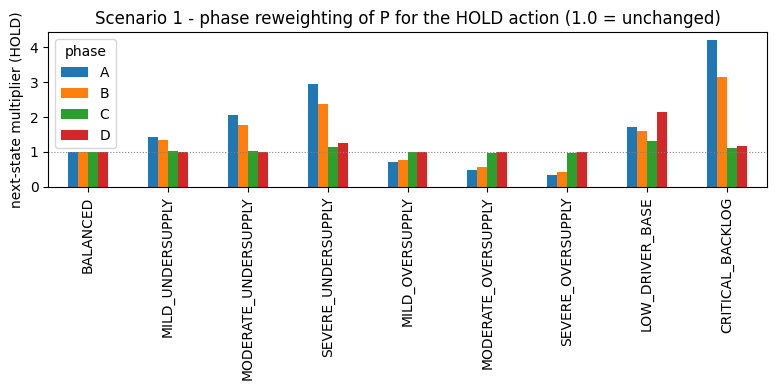

                         A     B     C     D
BALANCED              1.00  1.00  1.00  1.00
MILD_UNDERSUPPLY      1.43  1.33  1.02  1.00
MODERATE_UNDERSUPPLY  2.05  1.77  1.03  1.00
SEVERE_UNDERSUPPLY    2.94  2.38  1.13  1.26
MILD_OVERSUPPLY       0.70  0.75  0.99  1.00
MODERATE_OVERSUPPLY   0.49  0.57  0.97  1.00
SEVERE_OVERSUPPLY     0.34  0.43  0.96  1.00
LOW_DRIVER_BASE       1.72  1.60  1.31  2.15
CRITICAL_BACKLOG      4.22  3.16  1.12  1.17

DEMAND_TILT_SCALE by action: {'HOLD': np.float64(1.0), 'RAISE_PRICE': np.float64(0.25), 'LOWER_PRICE': np.float64(1.0), 'DRIVER_INCENTIVE': np.float64(1.0), 'PAUSE_NEW_REQUESTS': np.float64(0.35)}


In [6]:
hold_tilt = {}
for ph, (dp, at, eff) in PHASE_PARAMS.items():
    hold_tilt[ph] = np.exp(0.30 * dp * 1.00 * lean + 0.45 * at * attrition_boost)
tilt_df = pd.DataFrame(hold_tilt, index=STATES)

fig, ax = plt.subplots(figsize=(8, 4))
tilt_df.plot(kind="bar", ax=ax)
ax.axhline(1.0, color="grey", lw=0.8, ls=":")
ax.set_ylabel("next-state multiplier (HOLD)")
ax.set_title("Scenario 1 - phase reweighting of P for the HOLD action (1.0 = unchanged)")
ax.legend(title="phase"); plt.tight_layout(); plt.show()
print(tilt_df.round(2))
print("\nDEMAND_TILT_SCALE by action:", dict(zip(ACTIONS, DEMAND_TILT_SCALE)))

## 2. Dynamic-programming solvers (finite horizon)

Both return a non-stationary policy `pi[t, s]` and value table `V[t, s]`, using the period-specific transition tensor `P_t`.

* Value Iteration — backward induction: one backward sweep of `T` Bellman-optimality backups; exact after `T` stage-backups.
* Policy Iteration — alternate an exact backward policy-evaluation sweep with a greedy improvement pass over every `(t, s)`; stop when no action changes.

They must return the same optimum — a correctness check.

In [7]:
def finite_horizon_value_iteration(P_time, R_time, horizon, terminal_value):
    """Backward induction with time-varying P and R. Returns (V, policy, n_backups, seconds)."""
    S = terminal_value.shape[0]
    V = np.zeros((horizon + 1, S))
    policy = np.zeros((horizon, S), dtype=int)
    V[horizon] = terminal_value
    n_backups = 0
    t0 = time.perf_counter()
    for t in range(horizon - 1, -1, -1):
        Q = R_time[t] + P_time[t] @ V[t + 1]        # (S, A)
        V[t] = Q.max(axis=1)
        policy[t] = Q.argmax(axis=1)
        n_backups += 1
    return V, policy, n_backups, time.perf_counter() - t0


def finite_horizon_policy_evaluation(P_time, R_time, horizon, terminal_value, policy):
    """Exact value of a fixed non-stationary policy via one backward sweep."""
    S = terminal_value.shape[0]
    V = np.zeros((horizon + 1, S))
    V[horizon] = terminal_value
    rows = np.arange(S)
    for t in range(horizon - 1, -1, -1):
        a = policy[t]
        V[t] = R_time[t][rows, a] + np.einsum("sn,n->s", P_time[t][rows, a], V[t + 1])
    return V


def finite_horizon_policy_iteration(P_time, R_time, horizon, terminal_value, max_iter=100):
    """Finite-horizon policy iteration. Returns (V, policy, n_iterations, seconds)."""
    S = terminal_value.shape[0]
    policy = np.zeros((horizon, S), dtype=int)      # start: HOLD everywhere
    n_iter = 0
    t0 = time.perf_counter()
    for _ in range(max_iter):
        n_iter += 1
        V = finite_horizon_policy_evaluation(P_time, R_time, horizon, terminal_value, policy)
        new_policy = np.zeros_like(policy)
        for t in range(horizon):
            Q = R_time[t] + P_time[t] @ V[t + 1]
            new_policy[t] = Q.argmax(axis=1)
        if np.array_equal(new_policy, policy):
            policy = new_policy
            break
        policy = new_policy
    secs = time.perf_counter() - t0
    V = finite_horizon_policy_evaluation(P_time, R_time, horizon, terminal_value, policy)
    return V, policy, n_iter, secs

print("Solvers defined.")

Solvers defined.


### 2.1 Experimental settings

| Parameter | Value | Notes |
|-----------|-------|-------|
| Horizon `T` | 12 | 2-hour episode, decisions every 10 min |
| Discount `gamma` | 1.0 (finite horizon) | no discounting for a fixed short episode |
| Transition model | time-varying `P_t`, 4 phases | evening peak -> late night |
| VI stopping rule | exact after `T` backward stage-backups | backward induction |
| PI initial policy | `HOLD` in every `(t, s)` | |
| PI stopping rule | policy unchanged over a full improvement pass | |
| Timing | best of 200 repeated solves (`time.perf_counter`) | solves are sub-millisecond |


In [8]:
def best_time(fn, repeats=200):
    """Robust wall-clock: fastest of several repeated runs."""
    best = float("inf")
    for _ in range(repeats):
        *_, secs = fn()
        best = min(best, secs)
    return best

V_vi, pi_vi, vi_backups, _ = finite_horizon_value_iteration(P_time, R_time, HORIZON, terminal_value)
V_pi, pi_pi, pi_iters, _ = finite_horizon_policy_iteration(P_time, R_time, HORIZON, terminal_value)

vi_time = best_time(lambda: finite_horizon_value_iteration(P_time, R_time, HORIZON, terminal_value))
pi_time = best_time(lambda: finite_horizon_policy_iteration(P_time, R_time, HORIZON, terminal_value))

print(f"Value Iteration : {vi_backups} backward stage-backups, {vi_time*1e3:.4f} ms")
print(f"Policy Iteration: {pi_iters} policy-improvement iterations, {pi_time*1e3:.4f} ms")
print("Optimal policies identical (VI vs PI)? ", np.array_equal(pi_vi, pi_pi))
print("Optimal value functions identical? ", np.allclose(V_vi, V_pi, atol=1e-9))

Value Iteration : 12 backward stage-backups, 0.0200 ms
Policy Iteration: 4 policy-improvement iterations, 0.1619 ms
Optimal policies identical (VI vs PI)?  True
Optimal value functions identical?  True


## 3. Optimal policy and value function

In [9]:
policy_df = pd.DataFrame(
    [[ACTIONS[pi_vi[t, s]] for s in range(S)] for t in range(HORIZON)],
    index=[f"t={t:2d} [{phase_of(t)[:4]}]" for t in range(HORIZON)], columns=STATES)
print("Optimal non-stationary policy pi*(t, s) [from Value Iteration]:")
policy_df

Optimal non-stationary policy pi*(t, s) [from Value Iteration]:


,BALANCED,MILD_UNDERSUPPLY,MODERATE_UNDERSUPPLY,SEVERE_UNDERSUPPLY,MILD_OVERSUPPLY,MODERATE_OVERSUPPLY,SEVERE_OVERSUPPLY,LOW_DRIVER_BASE,CRITICAL_BACKLOG
t= 0 [A],HOLD,RAISE_PRICE,RAISE_PRICE,PAUSE_NEW_REQUESTS,HOLD,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 1 [A],HOLD,RAISE_PRICE,RAISE_PRICE,PAUSE_NEW_REQUESTS,HOLD,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 2 [A],HOLD,RAISE_PRICE,RAISE_PRICE,PAUSE_NEW_REQUESTS,HOLD,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 3 [B],HOLD,RAISE_PRICE,RAISE_PRICE,PAUSE_NEW_REQUESTS,HOLD,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 4 [B],HOLD,RAISE_PRICE,RAISE_PRICE,PAUSE_NEW_REQUESTS,HOLD,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 5 [B],HOLD,RAISE_PRICE,RAISE_PRICE,PAUSE_NEW_REQUESTS,LOWER_PRICE,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 6 [C],HOLD,RAISE_PRICE,DRIVER_INCENTIVE,DRIVER_INCENTIVE,LOWER_PRICE,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 7 [C],HOLD,RAISE_PRICE,DRIVER_INCENTIVE,DRIVER_INCENTIVE,LOWER_PRICE,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 8 [C],HOLD,RAISE_PRICE,DRIVER_INCENTIVE,DRIVER_INCENTIVE,LOWER_PRICE,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS
t= 9 [D],HOLD,HOLD,DRIVER_INCENTIVE,DRIVER_INCENTIVE,HOLD,LOWER_PRICE,LOWER_PRICE,DRIVER_INCENTIVE,PAUSE_NEW_REQUESTS


In [10]:
value_df = pd.DataFrame(V_vi[:HORIZON], index=[f"t={t}" for t in range(HORIZON)],
                        columns=STATES)
print("Optimal value function V*(t, s):")
value_df.round(2)

Optimal value function V*(t, s):


,BALANCED,MILD_UNDERSUPPLY,MODERATE_UNDERSUPPLY,SEVERE_UNDERSUPPLY,MILD_OVERSUPPLY,MODERATE_OVERSUPPLY,SEVERE_OVERSUPPLY,LOW_DRIVER_BASE,CRITICAL_BACKLOG
t=0,78.60,73.20,62.91,45.43,72.52,65.78,57.77,61.97,41.17
t=1,72.93,67.54,57.25,39.76,66.84,60.09,52.04,56.30,35.51
t=2,67.28,61.88,51.58,34.10,61.12,54.32,46.15,50.63,29.85
t=3,61.70,56.15,45.91,28.51,55.25,48.28,39.93,44.93,24.29
t=4,55.91,50.37,40.15,22.75,49.41,42.39,33.79,39.15,18.52
t=5,50.15,44.58,34.39,17.07,43.56,36.01,26.36,33.37,12.76
t=6,44.66,38.62,28.25,12.75,37.03,27.18,16.97,27.74,7.60
t=7,38.80,32.81,22.47,7.05,31.17,21.10,10.62,21.91,1.82
t=8,32.95,27.07,16.75,1.53,25.28,14.59,3.47,16.10,-3.92
t=9,27.22,21.25,11.49,-4.05,19.25,6.33,-3.69,10.24,-10.07


In [11]:
first = pd.DataFrame({
    "V*(0, s)": V_vi[0].round(2),
    "pi*(0, s)": [ACTIONS[a] for a in pi_vi[0]],
}, index=STATES)
print("First-period optimal decision and value:")
first

First-period optimal decision and value:


,"V*(0, s)","pi*(0, s)"
BALANCED,78.60,HOLD
MILD_UNDERSUPPLY,73.20,RAISE_PRICE
MODERATE_UNDERSUPPLY,62.91,RAISE_PRICE
SEVERE_UNDERSUPPLY,45.43,PAUSE_NEW_REQUESTS
MILD_OVERSUPPLY,72.52,HOLD
MODERATE_OVERSUPPLY,65.78,LOWER_PRICE
SEVERE_OVERSUPPLY,57.77,LOWER_PRICE
LOW_DRIVER_BASE,61.97,DRIVER_INCENTIVE
CRITICAL_BACKLOG,41.17,PAUSE_NEW_REQUESTS


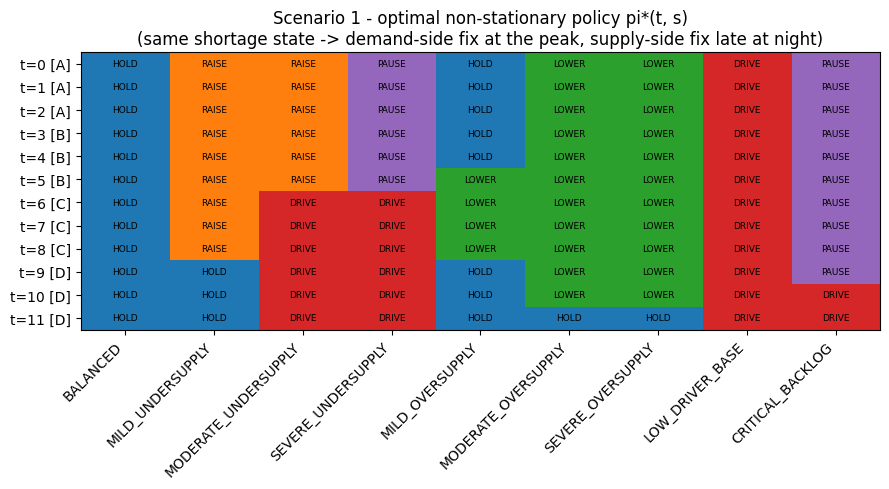

7 of 9 states change their optimal action over the horizon.


In [12]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(pi_vi, aspect="auto", cmap="tab10", vmin=0, vmax=9)
ax.set_xticks(range(S)); ax.set_xticklabels(STATES, rotation=45, ha="right")
ax.set_yticks(range(HORIZON)); ax.set_yticklabels([f"t={t} [{phase_of(t)}]" for t in range(HORIZON)])
for t in range(HORIZON):
    for s in range(S):
        ax.text(s, t, ACTIONS[pi_vi[t, s]][:5], ha="center", va="center", fontsize=6.5)
ax.set_title("Scenario 1 - optimal non-stationary policy pi*(t, s)\n"
             "(same shortage state -> demand-side fix at the peak, supply-side fix late at night)")
plt.tight_layout(); plt.show()

n_switch = sum(len(set(pi_vi[:, s])) > 1 for s in range(S))
print(f"{n_switch} of {S} states change their optimal action over the horizon.")

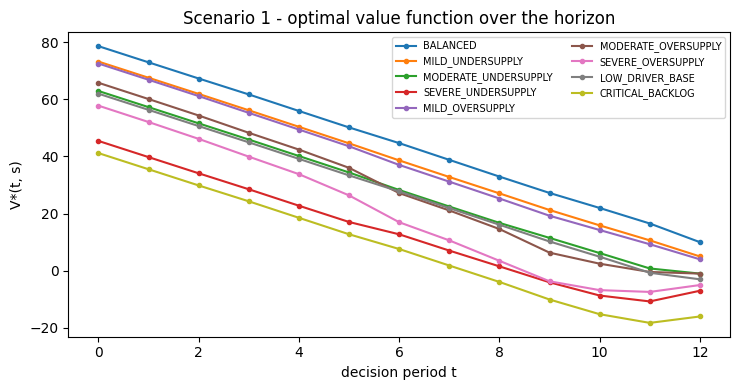

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for s in range(S):
    ax.plot(range(HORIZON + 1), V_vi[:, s], marker="o", ms=3, label=STATES[s])
ax.set_xlabel("decision period t"); ax.set_ylabel("V*(t, s)")
ax.set_title("Scenario 1 - optimal value function over the horizon")
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()

## 4. Robustness and algorithm comparison

### 4.1 Sensitivity of the optimal policy to the parameters
`P_base`, `R` and the phase parameters are hand-designed. We re-solve 300 MDPs with every such number perturbed ±10–15% and report how much of the optimal `(t, s)` policy is unchanged — a check that the conclusions are not an artefact of the exact values.

In [14]:
def build_P_time(P_base, phase_params, demand_scale, lean, attrition_boost):
    P_time = np.zeros((HORIZON, S, A, S))
    for t in range(HORIZON):
        dp, at, eff = phase_params[phase_of(t)]
        demand_tilt = np.exp(0.30 * dp * demand_scale[:, None] * lean[None, :])
        attrition_tilt = np.exp(0.45 * at * attrition_boost)
        tilt = demand_tilt * attrition_tilt[None, :]
        P_t = P_base.copy()
        for a in PRICE_ACTIONS:
            P_t[:, a] = eff * P_base[:, a] + (1 - eff) * P_base[:, a_idx["HOLD"]]
        P_t *= tilt[None, :, :]
        P_t /= P_t.sum(axis=2, keepdims=True)
        P_time[t] = P_t
    return P_time

rng = np.random.default_rng(0)
agree_t0, agree_grid = [], []
for _ in range(300):
    R_p = R * (1 + 0.10 * rng.uniform(-1, 1, R.shape))
    Pb_p = (P_base * (1 + 0.15 * rng.uniform(-1, 1, P_base.shape))).clip(1e-3, None)
    Pb_p /= Pb_p.sum(axis=2, keepdims=True)
    pp_p = {k: tuple(v * (1 + 0.15 * rng.uniform(-1, 1)) for v in val)
            for k, val in PHASE_PARAMS.items()}
    ds_p = DEMAND_TILT_SCALE * (1 + 0.15 * rng.uniform(-1, 1, DEMAND_TILT_SCALE.shape))
    Pt_p = build_P_time(Pb_p, pp_p, ds_p, lean, attrition_boost)
    Rt_p = np.broadcast_to(R_p, (HORIZON, S, A))
    _, pi_p, *_ = finite_horizon_value_iteration(Pt_p, Rt_p, HORIZON, terminal_value)
    agree_t0.append((pi_p[0] == pi_vi[0]).mean())
    agree_grid.append((pi_p == pi_vi).mean())

print(f"Over 300 perturbed MDPs (R +-10%, P_base +-15%, phase & tilt params +-15%):")
print(f"  first-period policy pi*(0,.) unchanged : {np.mean(agree_t0):.0%} on average (min {np.min(agree_t0):.0%})")
print(f"  full t x s policy grid unchanged       : {np.mean(agree_grid):.0%} on average (min {np.min(agree_grid):.0%})")

greedy = R.argmax(axis=1)
print(f"\n  a greedy (immediate-reward-only) policy differs from pi*(0,.) on "
      f"{(greedy != pi_vi[0]).sum()} of {S} states - i.e. DP genuinely changes the decision.")

Over 300 perturbed MDPs (R +-10%, P_base +-15%, phase & tilt params +-15%):
  first-period policy pi*(0,.) unchanged : 88% on average (min 56%)
  full t x s policy grid unchanged       : 87% on average (min 73%)

  a greedy (immediate-reward-only) policy differs from pi*(0,.) on 7 of 9 states - i.e. DP genuinely changes the decision.


### 4.2 Value Iteration vs Policy Iteration

Both solvers use the same finite-horizon model, so this only concerns *how* each reaches the optimum. Value Iteration is one backward pass of `T` stage-backups (exact after `T`); Policy Iteration repeats a full `T`-stage evaluation plus a greedy improvement (~4 sweeps). Fewer iterations for PI, but each is far heavier, so VI is faster in wall-clock here. The numbers are in the Section 2.1 output and the Section 6 table.

## 5. Simulating the optimal policies

20,000 Monte-Carlo episodes of the time-varying MDP: the start state is drawn from a fixed distribution, the non-stationary optimal policy is followed for 12 periods, and the total undiscounted reward (including the terminal reward) is recorded. Compared: `VI-optimal`, `PI-optimal` (same policy), and an `always-HOLD` baseline.

In [15]:
START_DIST = np.array([0.16, 0.14, 0.12, 0.10, 0.12, 0.10, 0.08, 0.11, 0.07])
START_DIST /= START_DIST.sum()
N_EPISODES = 20_000

def simulate(P_time, R_time, policy, horizon, terminal_value, start_dist, n_episodes, seed):
    rng = np.random.default_rng(seed)
    totals = np.empty(n_episodes)
    for e in range(n_episodes):
        s = rng.choice(S, p=start_dist)
        g = 0.0
        for t in range(horizon):
            a = policy[t, s]
            g += R_time[t, s, a]
            s = rng.choice(S, p=P_time[t, s, a])
        g += terminal_value[s]
        totals[e] = g
    return totals

always_hold = np.zeros((HORIZON, S), dtype=int)

ret_vi   = simulate(P_time, R_time, pi_vi,             HORIZON, terminal_value, START_DIST, N_EPISODES, seed=1)
ret_pi   = simulate(P_time, R_time, pi_pi,             HORIZON, terminal_value, START_DIST, N_EPISODES, seed=1)
ret_hold = simulate(P_time, R_time, always_hold,       HORIZON, terminal_value, START_DIST, N_EPISODES, seed=1)

sim_df = pd.DataFrame({
    "policy": ["VI-optimal", "PI-optimal", "always-HOLD baseline"],
    "avg total reward": [ret_vi.mean(), ret_pi.mean(), ret_hold.mean()],
    "std": [ret_vi.std(), ret_pi.std(), ret_hold.std()],
    "avg reward / period": [ret_vi.mean()/HORIZON, ret_pi.mean()/HORIZON, ret_hold.mean()/HORIZON],
})
print(f"Average reward over {N_EPISODES:,} simulated episodes:")
sim_df.round(3)

Average reward over 20,000 simulated episodes:


,policy,avg total reward,std,avg reward / period
0,VI-optimal,64.561,24.446,5.380
1,PI-optimal,64.561,24.446,5.380
2,always-HOLD baseline,17.818,62.025,1.485


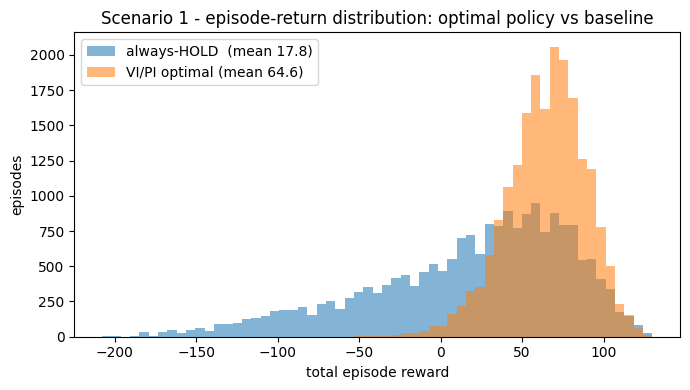

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(min(ret_hold.min(), ret_vi.min()), max(ret_vi.max(), ret_hold.max()), 60)
ax.hist(ret_hold, bins=bins, alpha=.55, label=f"always-HOLD  (mean {ret_hold.mean():.1f})")
ax.hist(ret_vi,   bins=bins, alpha=.55, label=f"VI/PI optimal (mean {ret_vi.mean():.1f})")
ax.set_xlabel("total episode reward"); ax.set_ylabel("episodes")
ax.set_title("Scenario 1 - episode-return distribution: optimal policy vs baseline")
ax.legend(); plt.tight_layout(); plt.show()

In [17]:
# Trace one example episode under the optimal policy
rng = np.random.default_rng(7)
s = rng.choice(S, p=START_DIST)
rows = []
total = 0.0
for t in range(HORIZON):
    a = pi_vi[t, s]
    rows.append({"t": t, "phase": phase_of(t), "state": STATES[s],
                 "action": ACTIONS[a], "reward": R_time[t, s, a]})
    total += R_time[t, s, a]
    s = rng.choice(S, p=P_time[t, s, a])
rows.append({"t": "end", "phase": "", "state": STATES[s],
             "action": "(terminal)", "reward": terminal_value[s]})
total += terminal_value[s]

episode = pd.DataFrame(rows).set_index("t")
print("total episode reward =", round(total, 1))
episode

total episode reward = 81.0


,phase,state,action,reward
t,,,,
0,A,MILD_OVERSUPPLY,HOLD,4.0
1,A,MODERATE_OVERSUPPLY,LOWER_PRICE,-3.0
2,A,MILD_OVERSUPPLY,HOLD,4.0
3,B,BALANCED,HOLD,10.0
4,B,BALANCED,HOLD,10.0
5,B,MILD_OVERSUPPLY,LOWER_PRICE,2.0
6,C,BALANCED,HOLD,10.0
7,C,MILD_OVERSUPPLY,LOWER_PRICE,2.0
8,C,MILD_OVERSUPPLY,LOWER_PRICE,2.0


## 6. Results summary (assignment comparison table)

In [18]:
def pol0(policy):
    row = policy[0] if policy.ndim == 2 else policy
    return " / ".join(ACTIONS[a][:4] for a in row)

summary = pd.DataFrame([
    dict(Scenario=1, Algorithm="Policy Iteration (finite horizon, time-varying)",
         **{"Optimal policy pi*(0,.)": pol0(pi_pi),
            "Mean V*(0,.)": round(float(V_pi[0].mean()), 3),
            "Convergence time (ms)": round(pi_time * 1e3, 4),
            "Iterations": pi_iters,
            "Avg reward (sim)": round(float(ret_pi.mean()), 3)}),
    dict(Scenario=1, Algorithm="Value Iteration (finite horizon, time-varying)",
         **{"Optimal policy pi*(0,.)": pol0(pi_vi),
            "Mean V*(0,.)": round(float(V_vi[0].mean()), 3),
            "Convergence time (ms)": round(vi_time * 1e3, 4),
            "Iterations": vi_backups,
            "Avg reward (sim)": round(float(ret_vi.mean()), 3)}),
])
summary


,Scenario,Algorithm,"Optimal policy pi*(0,.)","Mean V*(0,.)",Convergence time (ms),Iterations,Avg reward (sim)
0,1,"Policy Iteration (finite horizon, time-varying)",HOLD / RAIS / RAIS / PAUS / HOLD / LOWE / LOWE...,62.149,0.1619,4,64.561
1,1,"Value Iteration (finite horizon, time-varying)",HOLD / RAIS / RAIS / PAUS / HOLD / LOWE / LOWE...,62.149,0.0200,12,64.561


## 7. Key findings

* Value Iteration and Policy Iteration return the identical optimal policy and value function (checked in Section 2.1), with matching simulated average rewards.
* The optimal policy is non-stationary: 7 of the 9 states change their optimal action over the 12 periods.
* The optimal policy earns 64.6 on average versus 17.8 for the always-HOLD baseline (Section 5).

Interpretation, algorithm strengths / limitations, and the comparative study are in the report.